In [28]:
from datasets import load_dataset
from PIL import Image

In [29]:
dataset = load_dataset("naver-clova-ix/cord-v2")

In [30]:
image=dataset["train"][0]["image"]

print (image.size)
print(image.mode)

(864, 1296)
RGB


In [31]:
def process_image(image):
    image=image.convert("RGB")
    image=image.resize((224,224))
    return image

In [32]:
processed_image= process_image(image)

print("original",image.size)
print("processed",processed_image.size)

original (864, 1296)
processed (224, 224)


In [33]:
def resize_aspect(image):
    
    target_width,target_height=(224,224)
    original_width,original_height=image.size

    scale=min(target_width/original_width,target_height/original_height)
    
    new_width=int(original_width*scale)
    new_height=int(original_height*scale)

    image=image.resize((new_width,new_height))
    
    return image

In [34]:
preprocess_image=resize_aspect(image)

print("original",image.size)
print("processed",preprocess_image.size)

original (864, 1296)
processed (149, 224)


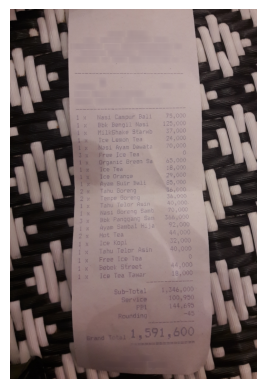

In [35]:
import matplotlib.pyplot as plt

plt.imshow(image)
plt.axis("off")
plt.show()

In [36]:
from PIL import ImageOps

def padding(image):

    target_w,target_h=(224,224)
    w,h=image.size

    pad_w=target_w - w
    pad_h=target_h - h

    left=pad_w//2
    right=pad_w-left

    top=pad_h//2
    bottom=pad_h-top

    image=ImageOps.expand(
        image,
        border=(left,top,right,bottom),
        fill="white"
    )

    return image

    

    

In [37]:
image=dataset["train"][0]["image"]
process_image=resize_aspect(image)
padd_image=padding(process_image)
print("original",image.size)
print("processed",padd_image.size)

original (864, 1296)
processed (224, 224)


In [38]:
import numpy as np

image_array = np.array(padd_image)

print(image_array.shape)
print(image_array.dtype)
print(image_array.min())
print(image_array.max())

(224, 224, 3)
uint8
0
255


In [39]:
normalized = image_array / 255.0

print(normalized.shape)
print(normalized.dtype)
print(normalized.min())
print(normalized.max())

(224, 224, 3)
float64
0.0
1.0


In [40]:
import numpy as np
from PIL import ImageOps


def preprocess_image(image, target_size=(224, 224)):
    # 1. Convert to RGB
    image = image.convert("RGB")

    # 2. Get original dimensions
    original_width, original_height = image.size

    target_width, target_height = target_size

    # 3. Calculate scale while preserving aspect ratio
    scale = min(
        target_width / original_width,
        target_height / original_height
    )

    # 4. Calculate new dimensions
    new_width = int(original_width * scale)
    new_height = int(original_height * scale)

    # 5. Resize
    image = image.resize((new_width, new_height))

    # 6. Calculate padding
    pad_width = target_width - new_width
    pad_height = target_height - new_height

    left = pad_width // 2
    right = pad_width - left

    top = pad_height // 2
    bottom = pad_height - top

    # 7. Add white padding
    image = ImageOps.expand(
        image,
        border=(left, top, right, bottom),
        fill="white"
    )

    # 8. Convert to NumPy array
    image_array = np.array(image)

    # 9. Normalize pixels
    image_array = image_array.astype(np.float32) / 255.0

    return image_array

In [41]:
sample = dataset["train"][1]["image"]

processed = preprocess_image(sample)

print("Shape:", processed.shape)
print("Data type:", processed.dtype)
print("Min:", processed.min())
print("Max:", processed.max())

Shape: (224, 224, 3)
Data type: float32
Min: 0.007843138
Max: 1.0


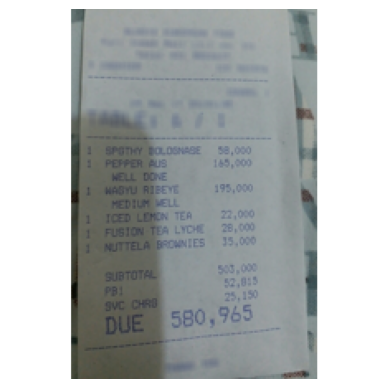

In [42]:
import matplotlib.pyplot as plt

plt.imshow(processed)
plt.axis("off")
plt.show()

In [43]:
def preprocess_dataset(dataset_split):
    processed_images = []

    for sample in dataset_split:
        image = sample["image"]

        processed_image = preprocess_image(image)

        processed_images.append(processed_image)

    return processed_images

In [44]:
train_images = preprocess_dataset(dataset["train"])
val_images = preprocess_dataset(dataset["validation"])
test_images = preprocess_dataset(dataset["test"])

In [45]:
print("Train:", len(train_images))
print("Validation:", len(val_images))
print("Test:", len(test_images))

Train: 800
Validation: 100
Test: 100


In [48]:
def create_sample(sample):
    image = preprocess_image(sample["image"])
    labels = extract_labels(sample["ground_truth"])

    return {
        "image": image,
        "labels": labels
    }

In [49]:
sample = create_sample(dataset["train"][0])

print(sample["image"].shape)
print(sample["labels"])

(224, 224, 3)
{'items': [], 'quantities': [], 'prices': []}
